In [3]:
import pandas as pd
import numpy as np

In [4]:
events = pd.read_excel("NHL-playoffs-2026.xlsx")
events.shape

(29710, 39)

## Задание 1

In [5]:
events.iloc[:5, [2, 3, 4, 9, 12, 13]]

,Game ID,Date,Away Team,Elapsed Time,Play Length,Play Type
0,2025030111,2026-04-19,Boston Bruins,00:00,00:00,period-start
1,2025030111,2026-04-19,Boston Bruins,00:00,00:00,faceoff
2,2025030111,2026-04-19,Boston Bruins,00:13,00:13,hit
3,2025030111,2026-04-19,Boston Bruins,00:14,00:01,hit
4,2025030111,2026-04-19,Boston Bruins,00:19,00:05,hit


прочитала файл NHL-playoffs-2026.xlsx с помощью pd.read_excel() и сохранила его в таблицу events. посмотрели размер таблицы, первые строки и типы данных, чтобы разобраться в структуре событий

In [6]:
events.dtypes

Unnamed: 0                               int64
Dataset                                    str
Game ID                                  int64
Date                                       str
Away Team                                  str
Home Team                                  str
Cumulated Away Score                     int64
Cumulated Home Score                     int64
Period                                   int64
Elapsed Time                               str
Remaining Time                             str
Play ID                                  int64
Play Length                                str
Play Type                                  str
Play Subtype                               str
Play Zone                                  str
Team Making the Play                       str
Player in the Event #1                     str
Player in the Event #2                     str
Player in the Event #3                     str
X Coordinate on the Ice Rink           float64
Y Coordinate 

## Задание 2

In [7]:
games = events.groupby("Game ID").agg(**{
    "Date": ("Date", "first"),
    "Away Team": ("Away Team", "first"),
    "Home Team": ("Home Team", "first"),
    "Away Score": ("Cumulated Away Score", "max"),
    "Home Score": ("Cumulated Home Score", "max"),
    "Last Period": ("Period", "max"),
})

def format_outcome(period):
    overtime = max(0, period - 3)
    if overtime == 0:
        return "Final"
    if overtime == 1:
        return "Final/OT"
    return f"Final/{overtime}OT"

games["Outcome"] = games.pop("Last Period").map(format_outcome)


In [8]:
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [9]:
games.iloc[-5:,-4:]


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


сгруппировала события по идентификатору Game ID с помощью .groupby().agg(). дату и названия команд взяла из первой строки каждой группы, итоговый счёт - как максимум накопа числа голов. по максимальному номеру периода определила исход: Final, Final/OT, Final/2OT

## Задание 3

In [10]:
def gameInfo(gameId):
    game = games.loc[gameId]

    return (
        f"{game['Home Team']} - {game['Away Team']} "
        f"({game['Home Score']} - {game['Away Score']}, "
        f"{game['Outcome']}, {pd.to_datetime(game['Date']):%Y-%m-%d})"
    )

In [11]:
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


написала gameInfo(gameId), которая получает строку из games через .loc[gameId]. из этой строки формируется описание. перед форматированием дату преобразовали через pd.to_datetime(), поскольку в исходных данных она хранится строкой

## Задание 4

In [12]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
games["Total Score"].describe()

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

 применила .describe(), чтобы получить количество матчей, среднее число голов, стандартное отклонение, минимум, максимум и квартили. Эти показатели позволяют оценить типичную результативность и её разброс

## Задание 5

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

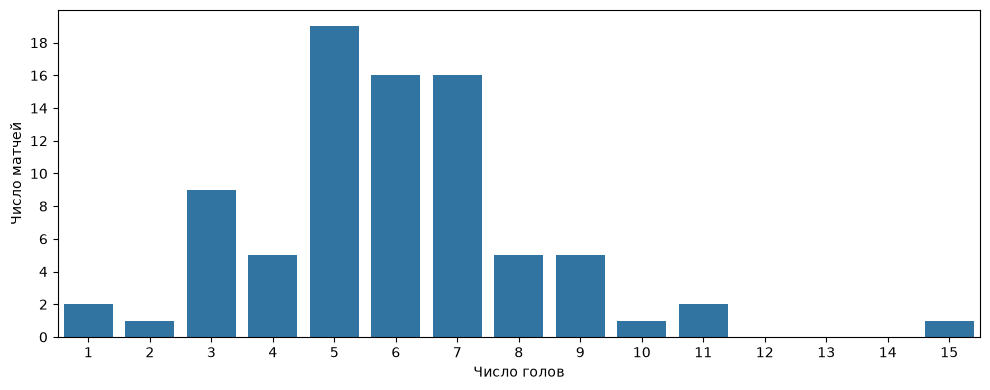

In [14]:
plt.figure(figsize=(10, 4))
ax = sns.countplot(
    data=games,
    x="Total Score",
    order=range(int(games["Total Score"].min()), int(games["Total Score"].max()) + 1),
)
ax.set_xlabel("Число голов")
ax.set_ylabel("Число матчей")
ax.set_ylim(0, 20)
ax.set_yticks(range(0, 20, 2))
plt.tight_layout()
plt.show()


- распределение не является нормальным, а скорее пуассоновским. 19 матчей заканчиваются на 5 голах.

- значения упираются в естественную границу игры - меньше нуля голов не может быть, а плэйофф играют до первого гола

- использовала sns.countplot(), который подсчитывает число матчей для каждого значения Total Score. На горизонтальной оси показали количество голов, на вертикальной количество матчей


## Задание 6

In [ ]:
min_score = games["Total Score"].min()
max_score = games["Total Score"].max()

min_games = games[games["Total Score"] == min_score]
max_games = games[games["Total Score"] == max_score]

print("Нерезультативные")
for game_id in min_games.index:
    print(gameInfo(game_id))

print("\nРезультативные")
for game_id in max_games.index:
    print(gameInfo(game_id))


Нерезультативные
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)

Результативные
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


## Задание 7

In [16]:
player_columns = [
    f"{team} Team's Player on the Ice #{number}"
    for team in ["Away", "Home"]
    for number in range(1, 7)
] + ["Away Team's Goalie", "Home Team's Goalie"]


players = events.melt(
    id_vars="Game ID",
    value_vars=player_columns,
    value_name="Player",
)

player_counts = players.groupby("Game ID")["Player"].nunique()

most_players = player_counts[player_counts == player_counts.max()].to_frame("Player Count")
most_players.insert(0, "Game Info", most_players.index.map(gameInfo))
most_players


,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


## Задание 8

In [17]:
shot_mask = events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"])
shots = events[shot_mask].copy()

is_home = shots["Team Making the Play"] == shots["Home Team"]
home_defends_left = shots["Home Team's Defending Side"] == "left"


shoots_right = (is_home & home_defends_left) | (~is_home & ~home_defends_left)
goal_x = np.where(shoots_right, 89, -89)

x = shots["X Coordinate on the Ice Rink"]
y = shots["Y Coordinate on the Ice Rink"]

dx = x - goal_x
dy = np.maximum(y.abs() - 3, 0)

events["Shot Length"] = np.nan
events.loc[shot_mask, "Shot Length"] = np.sqrt(dx ** 2 + dy ** 2)

events.loc[shot_mask, ["Game ID", "Play Type", "Shot Length"]]


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


отобрала события shot-on-goal, goal и missed-shot. по атакующей команде и полю Home Team's Defending Side определила координату нужных ворот. расстояние рассчитала до ближайшей точки створа: горизонт сост = x − X, а вертикальная = max(|y| − 3, 0). из суммы квадратов этих составляющих извлекли корень и записали результат в Shot Length

## Задание 9

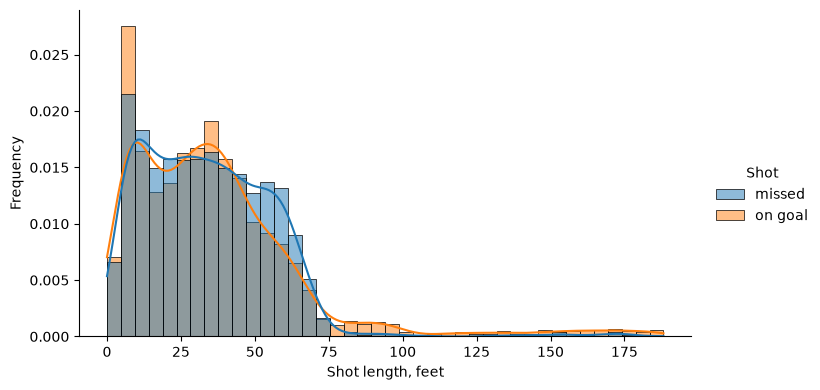

In [18]:
shot_distribution = events.loc[
    events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"]),
    ["Play Type", "Shot Length"],
].copy()
shot_distribution["Shot"] = shot_distribution["Play Type"].map({
    "shot-on-goal": "on goal",
    "goal": "on goal",
    "missed-shot": "missed",
})

g = sns.displot(
    data=shot_distribution,
    x="Shot Length",
    hue="Shot",
    hue_order=["missed", "on goal"],
    kind="hist",
    stat="density",
    common_norm=False,
    bins=40,
    kde=True,
    element="bars",
    alpha=0.5,
    edgecolor="black",
    linewidth=0.5,
    height=4,
    aspect=1.8,
)
g.set_axis_labels("Shot length, feet", "Frequency")
plt.show()


- почти все броски выполняются из зоны атаки (0-70 футов). после 70ти частота резко падает

- вблизи ворот частота голов (доля бросков в створ) выше

- на дистации 45-70 относительно синей линии - больше промахов. с увеличением расстояния попасть в створ сложнее (шокинг ньюз)

- хвост - дальние броски или выбросы шайбы со своей половины, которые доходят до створа и скорее всего отражаются вратарём или это броски в пустые ворота.



## Задание 10

In [38]:
unblocked_shots = events[
    events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"])
]

numshots = (
    unblocked_shots.groupby(["Game ID", "Team Making the Play", "Play Type"])
    .size()
    .unstack(fill_value=0)
)

numshots["Shots on Goal"] = numshots["shot-on-goal"] + numshots["goal"]
numshots["All Shots"] = numshots["Shots on Goal"] + numshots["missed-shot"]
numshots["Share of Shots on Goal"] = numshots["Shots on Goal"] / numshots["All Shots"]

numshots["Share of Shots on Goal"]


Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [39]:
numshots["Share of Shots on Goal"].mean()

np.float64(0.6391504136028602)

In [40]:
numshots["Share of Shots on Goal"].max()

np.float64(0.8604651162790697)

In [41]:
numshots["Share of Shots on Goal"].min()

np.float64(0.35294117647058826)

- в среднем 64%

- максимум 86%

- минимум 35%

- разница между соперниками в одном матче обычно невелика (в пределах нескольких процентных пунктов). 

- высокая доля точных бросков сама по себе не гарантирует победу (матче 2025030416 доли у Carolina (0,639) и Vegas (0,595) близки, результат вероятнее всего определили реализация моментов и игра вратарей.

## Задание 11

In [20]:
avgnumshots = numshots["Share of Shots on Goal"].groupby("Team Making the Play").mean()

In [22]:
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64

In [23]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64

- команды, у которых в названии есть животные, играют хуже чем те, у которых их нет

- разница между наибольшим и наименьшем 15%

- вероятно, доля попаданий в створ больше говорит о стиле игры, чем о силе команды. команды, которые много бросают shot on goal и с острых углов, чаще промахиваются, зато создают опасные моменты. команды, которые бросают аккуратно издалека, чаще получают goal, но вратарю такие броски отражать легче

## Задание 12

In [43]:
avgshots = (
    numshots.groupby("Team Making the Play")[["Shots on Goal", "goal"]]
    .mean()
    .rename(columns={"Shots on Goal": "Shot", "goal": "Goal"})
)
avgshots


Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.666667,3.250000
Boston Bruins,25.166667,2.000000
Buffalo Sabres,30.461538,3.307692
Carolina Hurricanes,31.631579,3.473684
Colorado Avalanche,32.153846,3.384615
Dallas Stars,31.000000,2.500000
Edmonton Oilers,28.333333,3.500000
Los Angeles Kings,25.250000,1.250000
Minnesota Wild,28.727273,3.727273


## Задание 13

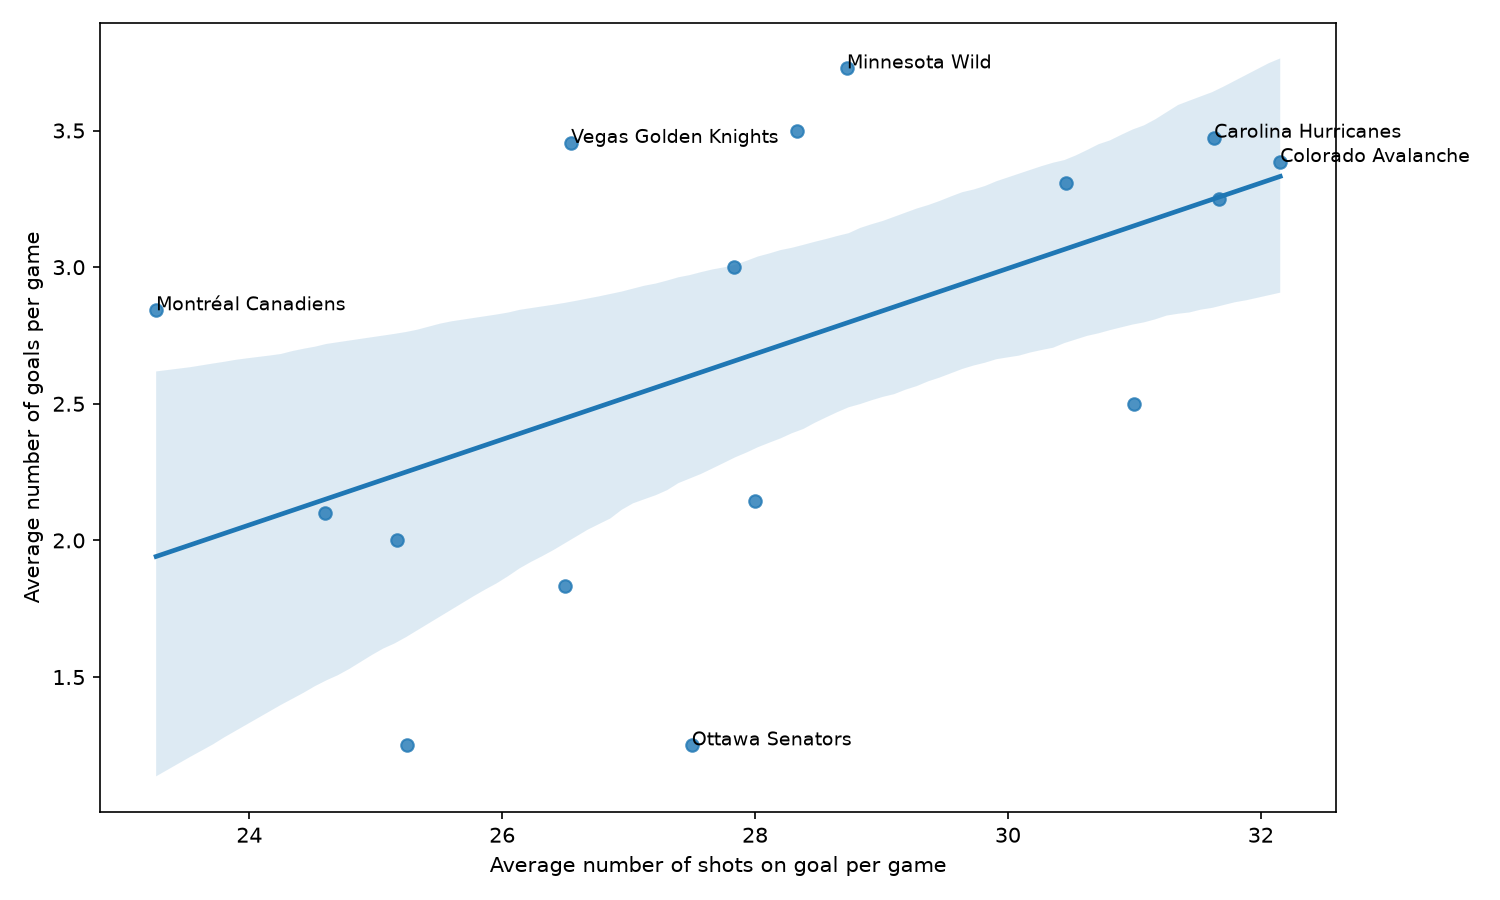

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.regplot(data=avgshots, x="Shot", y="Goal", seed=0)
ax.set_xlabel("Average number of shots on goal per game")
ax.set_ylabel("Average number of goals per game")

teams_to_label = [
    "Minnesota Wild",
    "Vegas Golden Knights",
    "Carolina Hurricanes",
    "Colorado Avalanche",
    "Montréal Canadiens",
    "Ottawa Senators",
]
for team in teams_to_label:
    ax.annotate(
        team,
        (avgshots.loc[team, "Shot"], avgshots.loc[team, "Goal"]),
        fontsize=9,
    )
plt.tight_layout()
plt.show()


In [44]:
avgshots["Shot"].corr(avgshots["Goal"])

np.float64(0.5207961205304793)

- умеренная положительная связь

- corr = 0.52

- наблюдаются выбросы  Minnesota Wild, кол-во ударов имеет вклад, но объясняет

- количество бросков в створ неполный показатель атаки. не менее важны качество моментов (дистанция и угол броска, добивания) и игра вратарей. кроме того, у нас всего 16 точек и команды сыграли разное число матчей, так что к выводу стоит относиться осторожно (не спеша, аккуратненько)

## Задание 14

In [25]:
all_shot_types = ["shot-on-goal", "goal", "missed-shot", "blocked-shot"]
shots_per_game = (
    events[events["Play Type"].isin(all_shot_types)]
    .groupby("Game ID")
    .size()
)
idxmax = shots_per_game.idxmax()
print(gameInfo(idxmax))
print("Total shots:", shots_per_game.loc[idxmax])


Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Total shots: 208


## Задание 15

In [30]:
from rink import plot_rink

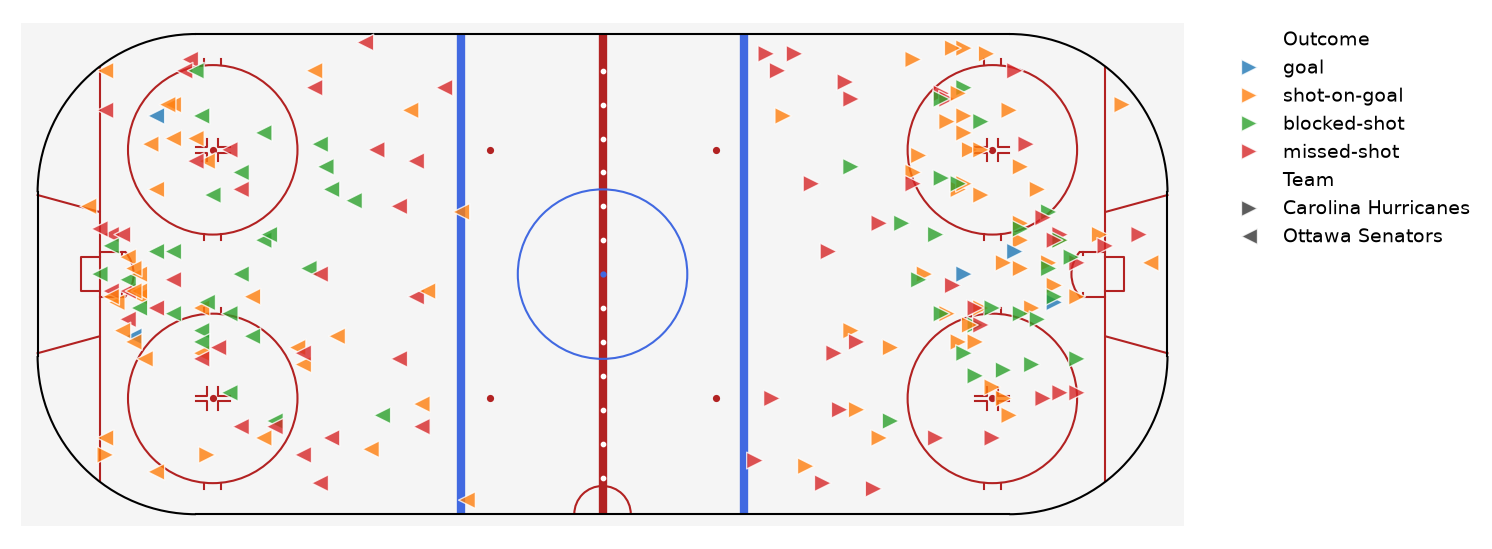

In [ ]:
match_shots = events[
    (events["Game ID"] == idxmax) & events["Play Type"].isin(all_shot_types)
].copy()


odd_period = match_shots["Period"] % 2 == 1
match_shots["Plot X"] = match_shots["X Coordinate on the Ice Rink"]
match_shots["Plot Y"] = match_shots["Y Coordinate on the Ice Rink"]
match_shots.loc[odd_period, ["Plot X", "Plot Y"]] *= -1

match_shots["Outcome"] = match_shots["Play Type"]
match_shots["Team"] = match_shots["Team Making the Play"]

plt.figure(figsize=(11, 4.5))
plot_rink()
ax = sns.scatterplot(
    data=match_shots,
    x="Plot X",
    y="Plot Y",
    hue="Outcome",
    hue_order=["goal", "shot-on-goal", "blocked-shot", "missed-shot"],
    style="Team",
    style_order=[games.loc[idxmax, "Home Team"], games.loc[idxmax, "Away Team"]],
    markers={
        games.loc[idxmax, "Home Team"]: ">",
        games.loc[idxmax, "Away Team"]: "<",
    },
    s=65,
    alpha=0.8,
)
ax.set_aspect("equal")
ax.set_xlim(-104, 104)
ax.set_ylim(-46, 46)
ax.set_axis_off()
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
plt.show()


выбрала все броски найденного матча и создала отдельные колонки координат для графика. в нечётных периодах преобразование из (x, y) в (-x, −y), чтобы хозяева всегда атаковали правые ворота, а гости левые. площадку нарисовала функцией plot_rink(), события через sns.scatterplot(). цвет это исход броска, а треугольники направление атаки команд

## Задание 16

In [ ]:
goals = events[events["Play Type"] == "goal"]
goal_counts = goals["Player in the Event #1"].value_counts()
goal_counts.index.name = "Player"
goal_counts.name = "Goals"
goal_counts.nlargest(10)


Player
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: Goals, dtype: int64

## Задание 17

In [ ]:
assist_counts = (
    goals[["Player in the Event #2", "Player in the Event #3"]]
    .melt(value_name="Player")["Player"]
    .value_counts()
)
assist_counts.index.name = "Player"
assist_counts.name = "Assists"
assist_counts.nlargest(10)


Player
Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: Assists, dtype: int64

для событий goal взяла колонки Player in the Event #2 и Player in the Event #3. объединили их в одну колонку через .melt() и посчитала частоту каждого имени. пропуски не учитываются

## Задание 18

In [ ]:
points = pd.concat([goal_counts, assist_counts], axis=1).fillna(0).astype(int)
points["Points"] = points["Goals"] + points["Assists"]
points.nlargest(10, "Points")


,Goals,Assists,Points
Player,,,
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16


## Задание 19

In [ ]:
player_columns = [
    f"{team} Team's Player on the Ice #{number}"
    for team in ["Away", "Home"]
    for number in range(1, 7)
] + ["Away Team's Goalie", "Home Team's Goalie"]

player_games = (
    events.melt(id_vars="Game ID", value_vars=player_columns, value_name="Player")
    .dropna(subset=["Player"])
    .groupby("Player")["Game ID"]
    .nunique()
)

shots_by_player = (
    events[events["Play Type"].isin(["shot-on-goal", "goal"])]
    ["Player in the Event #1"]
    .value_counts()
)
shots_per_player = pd.DataFrame({
    "Games": player_games,
    "Shots on Goal": shots_by_player.reindex(player_games.index, fill_value=0),
})
shots_per_player["Shots per Game"] = shots_per_player["Shots on Goal"] / shots_per_player["Games"]
shots_per_player.nlargest(10, "Shots per Game")


,Games,Shots on Goal,Shots per Game
Player,,,
Jason Robertson,6,30,5.000000
Dylan Guenther,6,27,4.500000
Nikita Kucherov,7,31,4.428571
Matt Boldy,11,48,4.363636
Quinton Byfield,4,17,4.250000
Darren Raddysh,7,28,4.000000
Joel Eriksson Ek,6,24,4.000000
Alex Laferriere,4,15,3.750000
David Pastrnak,6,22,3.666667


сначала определила число сыгранных матчей каждого игрока по колонкам присутствующих на льду ( уникальные Game ID для каждого имени). затем подсчитала его события shot-on-goal и goal и разделили их сумму на число матчей. в знаменателе учитываются и игры, в которых игрок выходил на лёд, но не попал в створ

## Задание 20

In [ ]:
hits_by_player = (
    events[events["Play Type"] == "hit"]["Player in the Event #1"]
    .value_counts()
)
hits_per_player = pd.DataFrame({
    "Games": player_games,
    "Hits": hits_by_player.reindex(player_games.index, fill_value=0),
})
hits_per_player["Hits per Game"] = hits_per_player["Hits"] / hits_per_player["Games"]
hits_per_player.nlargest(10, "Hits per Game")


,Games,Hits,Hits per Game
Player,,,
Lawson Crouse,6,38,6.333333
Alex Turcotte,1,6,6.000000
Alexander Petrovic,1,6,6.000000
Yakov Trenin,9,51,5.666667
Dylan Cozens,4,22,5.500000
Vasily Podkolzin,6,32,5.333333
Carl Grundstrom,3,15,5.000000
Ivan Barbashev,22,110,5.000000
Marcus Foligno,11,55,5.000000


отобрала события hit и посчитала их по имени из Player in the Event #1. полученное количество разделила на число сыгранных матчей из задания 19. затем выбрала десять максимальных средних. при интерпретации учитываем размер выборки

## Задание 21

In [ ]:
home_goalies = events[["Game ID", "Home Team's Goalie"]].rename(
    columns={"Home Team's Goalie": "Goalie"}
)
home_goalies["Goals Against"] = (
    (events["Play Type"] == "goal")
    & (events["Team Making the Play"] == events["Away Team"])
).astype(int)

away_goalies = events[["Game ID", "Away Team's Goalie"]].rename(
    columns={"Away Team's Goalie": "Goalie"}
)
away_goalies["Goals Against"] = (
    (events["Play Type"] == "goal")
    & (events["Team Making the Play"] == events["Home Team"])
).astype(int)

goalie_games = (
    pd.concat([home_goalies, away_goalies], ignore_index=True)
    .dropna(subset=["Goalie"])
    .groupby(["Goalie", "Game ID"])["Goals Against"]
    .sum()
)

zero_goal_games = goalie_games[goalie_games == 0]
clean_goalies = sorted(zero_goal_games.index.get_level_values("Goalie").unique())
clean_goalies


['Andrei Vasilevskiy', 'Arturs Silovs', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Jakub Dobes', 'Joonas Korpisalo', 'Scott Wedgewood']

отдельно для хозяев и гостей сопоставили имя вратаря с голами противоположной команды в тех же строках событий. объединили данные и суммировала пропущенные голы для каждой пары «вратарь - игра». выбрала пары с нулём и составили список уникальных имён

## Задание 22

В каком периоде забивают больше всего голов?

In [37]:

games_by_period = events.groupby("Period")["Game ID"].nunique()
goals_by_period = (
    events[events["Play Type"] == "goal"]
    .groupby("Period")
    .size()
    .reindex(games_by_period.index, fill_value=0)
)

period_stats = pd.DataFrame({
    "Games": games_by_period,
    "Goals": goals_by_period,
})
period_stats["Goals per Game"] = period_stats["Goals"] / period_stats["Games"]

regular_periods = period_stats.loc[[1, 2, 3]]
overtime_periods = period_stats.loc[period_stats.index > 3].copy()


In [33]:
regular_periods

,Games,Goals,Goals per Game
Period,,,
1,82,145,1.768293
2,82,150,1.829268
3,82,169,2.060976


Больше всего голов забивают в 3 периоде

In [36]:
overtime_periods

,Games,Goals,Goals per Game
Period,,,
4,22,18,0.818182
5,4,4,1.000000


для каждого периода посчитали количество голов и число матчей, дошедших до этого периода. разделила эти показатели, получила среднее число голов за матч в этом периоде. овертаймы вывели отдельно (их меньше и они могут длиться менее 20 минут, поэтому для сравнения интенсивности забивания потребовалось бы учитывать фактическое игровое время)